In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, classification_report)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
path="/content/drive/MyDrive/Colab Notebooks/11.03.25.csv"
df = pd.read_csv(path)


In [ ]:
df.head()
df.tail()

,age,num_dependents,marital_status,education_level,employment_years,employment_type,region_code,annual_income,monthly_income,other_income,...,debt_to_income_ratio,monthly_debt_payment,avg_monthly_spend,transaction_count_monthly,online_transactions_ratio,overdraft_count,late_fee_count,account_age_years,bank_products_owned,default
14995,19,1,1,4,33,1,5,170709,14225.75000,34930,...,1.458394,3054,3237,139,0.415930,14,11,9,2,1
14996,33,5,2,3,7,0,2,196162,16346.83333,37082,...,0.457248,1239,4701,26,0.789680,15,3,0,1,1
14997,48,5,1,1,20,3,14,226085,18840.41667,27633,...,0.310761,6549,5266,223,0.213017,14,14,24,6,1
14998,23,3,2,4,30,0,12,171016,14251.33333,45268,...,0.228942,271,3217,354,0.848120,18,5,23,1,1
14999,70,5,1,2,22,2,16,153616,12801.33333,4312,...,0.141719,3419,4778,589,0.022178,6,9,23,5,1


In [ ]:
print(df.shape)

(15000, 37)


In [ ]:
print('\n=== DATASET INFO ===')
print(df.info())


=== DATASET INFO ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 37 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   age                        15000 non-null  int64  
 1   num_dependents             15000 non-null  int64  
 2   marital_status             15000 non-null  int64  
 3   education_level            15000 non-null  int64  
 4   employment_years           15000 non-null  int64  
 5   employment_type            15000 non-null  int64  
 6   region_code                15000 non-null  int64  
 7   annual_income              15000 non-null  int64  
 8   monthly_income             15000 non-null  float64
 9   other_income               15000 non-null  int64  
 10  income_stability_score     15000 non-null  float64
 11  credit_score               15000 non-null  int64  
 12  num_credit_cards           15000 non-null  int64  
 13  num_active_loans        

In [ ]:
print('\n=== BASIC STATISTICS ===')
print(df.describe())


=== BASIC STATISTICS ===
                age  num_dependents  marital_status  education_level  \
count  15000.000000    15000.000000    15000.000000     15000.000000   
mean      48.575200        2.497200        0.998133         3.000467   
std       17.888479        1.711273        0.823352         1.409751   
min       18.000000        0.000000        0.000000         1.000000   
25%       33.000000        1.000000        0.000000         2.000000   
50%       48.000000        3.000000        1.000000         3.000000   
75%       64.000000        4.000000        2.000000         4.000000   
max       79.000000        5.000000        2.000000         5.000000   

       employment_years  employment_type   region_code  annual_income  \
count       15000.00000     15000.000000  15000.000000   15000.000000   
mean           22.02020         1.506333      9.930267  132752.427400   
std            13.01096         1.121625      5.471593   67514.145147   
min             0.00000         0

In [ ]:
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({
    'Missing Values': missing,
    'Percentage (%)': missing_pct.round(2)
}).query('`Missing Values` > 0').sort_values('Percentage (%)', ascending=False)

print('\n=== MISSING VALUES ===')
print(missing_df)


=== MISSING VALUES ===
Empty DataFrame
Columns: [Missing Values, Percentage (%)]
Index: []


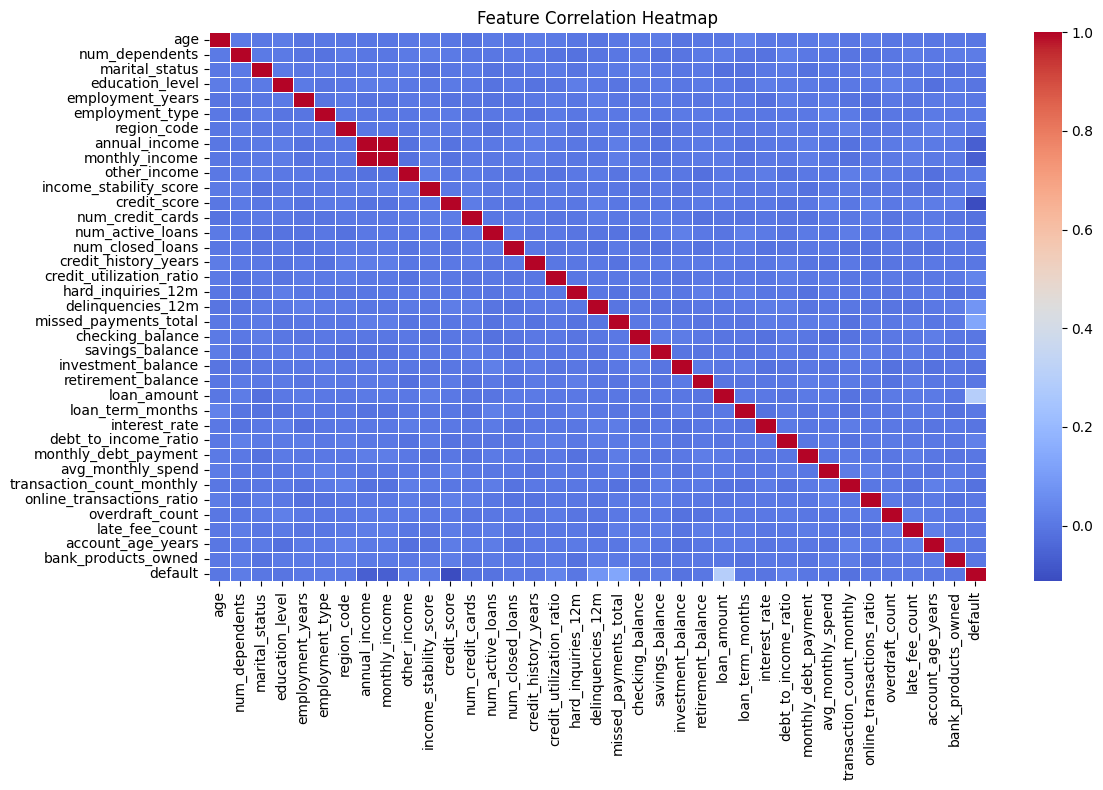

In [ ]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=False, cmap='coolwarm', linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

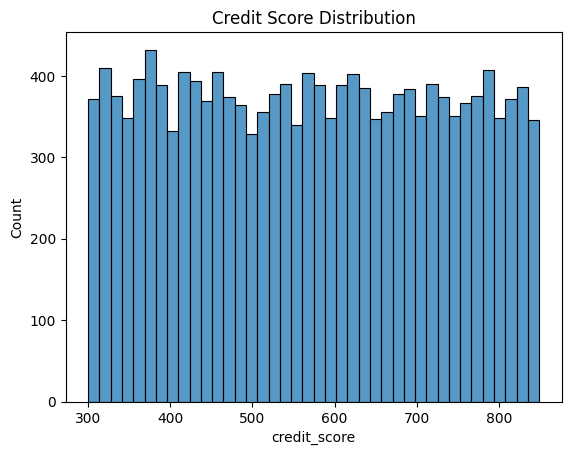

In [ ]:
plt.figure()

sns.histplot(df["credit_score"], bins=40)

plt.title("Credit Score Distribution")

plt.show()

In [ ]:
# Separate features from target variable
X = df.drop('default', axis=1)
y = df['default']
X_train, X_test, y_train , y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [ ]:
X = df.drop('default', axis=1)
y = df['default']

print(f'Features (X): {X.shape}  |  Target (y): {y.shape}')

Features (X): (15000, 36)  |  Target (y): (15000,)


In [ ]:
# Train-test split — 80% train, 20% test
# stratify=y keeps the same class ratio in both splits
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f'Train: {X_train.shape[0]:,} rows  |  Test: {X_test.shape[0]:,} rows')
print(f'Train default rate: {y_train.mean()*100:.1f}%  |  Test default rate: {y_test.mean()*100:.1f}%')

Train: 12,000 rows  |  Test: 3,000 rows
Train default rate: 96.5%  |  Test default rate: 96.5%


In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print('✅ Features scaled!')

✅ Features scaled!


In [ ]:
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_scaled, y_train)

print('Before SMOTE:', dict(pd.Series(y_train).value_counts()))
print('After  SMOTE:', dict(pd.Series(y_train_bal).value_counts()))
print(f'\n✅ Training set balanced: {X_train_bal.shape[0]:,} total samples')

NameError: name 'SMOTE' is not defined